# 09 — Connect human answers to actual classifier learning
**Goal:** make the real picture classifier learn from simulated human answers and track its accuracy as human seconds pass. Run Notebooks 00–08 first.
Select the **Project's (.venv)** kernel.

This is a small development demonstration. Notebook 10 repeats the experiment across people, seeds, starting sizes, and fatigue stories. Our human is still simulated. Classifier accuracy is measured on the 1,000 development evaluation images; the final 2,000-image test set stays reserved.

Reusable code: [classifier.py](../src/learn/classifier.py), [losses.py](../src/learn/losses.py), [al_loop.py](../src/learn/al_loop.py), and [stage2.py](../src/eval/stage2.py).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run
from src.eval.stage2 import load_learning_data, default_options, run_one
from src.sim.fatigue import Scenario
plt.rcParams.update({'figure.figsize': (8,4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Load features and check the separate roles
Pool pictures supply new questions. Calibration pictures adjust confidence.
Evaluation pictures measure accuracy. Their answers never train the classifier head.
The initial trusted labels are supplied separately; the learner has no list of true pool labels.

In [2]:
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
data = load_learning_data()
options = default_options()
options['budgets_seconds'] = [300,600]
scenario = Scenario(beta=1)
folder = save_run('notebook09', {'scenario': scenario.dictionary(), 'options': options, 'seed_size': 200, 'seed':42})
display(pd.Series({'Pool images': len(data['pool_ids']), 'Confidence-calibration images': len(data['calibration_ids']),
    'Evaluation images': len(data['evaluation_ids']), 'Features per image': data['features'].shape[1]}).to_frame('count'))

,count
Pool images,4000
Confidence-calibration images,1000
Evaluation images,1000
Features per image,512


## 2. Fix the time and session rules
- Each strategy starts with the same 200 trusted labels; their original cost is excluded equally.
- Annotators change at fixed 600-human-second boundaries, with a new fatigue belief.
- Questions, skipped opportunities, and gold checks all consume human time.
- A response finishing after a session/budget boundary is censored: its partial time counts,
  but its answer is not used. A measurement inside a response uses the previous trained model.
- Training occurs every 10 acquired answers. Pending answers stay buffered across sessions.
- Computer training time is recorded separately from human effort.

Practice is based on answered questions and capped at 200 per person. This prevents extrapolating the short-session practice trend indefinitely. QMDP uses a rolling look-ahead of at most 150 opportunities and 64 representative contexts to average future image arrivals.
These Stage-2 implementation choices are shared and documented, rather than tuned to a winner.

In [3]:
display(pd.Series(options, name='setting').to_frame())
image_roles = pd.read_csv(project / 'data/splits/images.csv')
names = image_roles.sort_values('true_label').drop_duplicates('true_label').true_category.tolist()
print('Current Stage-1 choice:', json.loads((project / 'outputs/stage1_latest.json').read_text())['assessment']['controller'])

,setting
budgets_seconds,"[300, 600]"
session_seconds,600
retrain_every_answers,10
initial_epochs,200
update_epochs,10
initial_lr,0.05
update_lr,0.01
targets_percent,"[75.0, 80.0]"
seed_label_cost,excluded; identical trusted starting labels wi...
session_rule,fixed 600-human-second shifts; crossing answer...


Current Stage-1 choice: qmdp


## 3. Turn an answer into a training instruction
A full answer allows one class. A "no" excludes one class. "Neither" excludes two.
The same loss function penalizes probability assigned outside the allowed set.
Each new example is weighted by its estimated reliability; trusted starting labels have weight 1.
Reliability is an estimate from the public human model and fatigue belief, not observed correctness.

In [4]:
from src.learn.losses import answer_target
examples = [('Full: dog',3,5), ('Verify cat: yes',1,0), ('Verify cat: no',1,1),
    ('Cat or dog: cat',2,0), ('Cat or dog: dog',2,1), ('Cat or dog: neither',2,2)]
rows = []
for description, action, answer in examples:
    allowed = answer_target(action, answer, np.array([3,5]))
    rows.append({'Human answer': description, 'Allowed class count': int(allowed.sum()),
        'Allowed classes': ', '.join(np.array(names)[allowed])})
display(pd.DataFrame(rows))

,Human answer,Allowed class count,Allowed classes
0,Full: dog,1,dog
1,Verify cat: yes,1,cat
2,Verify cat: no,9,"airplane, automobile, bird, deer, dog, frog, h..."
3,Cat or dog: cat,1,cat
4,Cat or dog: dog,1,dog
5,Cat or dog: neither,8,"airplane, automobile, bird, deer, frog, horse,..."


## 4. Run a short four-strategy demonstration
Use one seed, one fatigue setting, and a 600-second allowance. Every strategy starts from exactly the same model. The top-500 uncertain candidates refresh after each retraining.
Different classifiers can rank pictures differently; common random quantiles match the selection randomness, while the actual image IDs may diverge.

In [5]:
demos = []
for policy in ['qmdp','myopic','verify','full']:
    summary, run_folder = run_one(scenario, policy, seed_size=200, seed=42, options=options, data=data)
    demos.append({**summary, 'run_folder': str(run_folder.relative_to(project))})
demos = pd.DataFrame(demos)
demos.to_csv(folder / 'demonstration_runs.csv', index=False)
assert demos.initial_accuracy.max() - demos.initial_accuracy.min() < 1e-6
display(demos[['policy','initial_accuracy','accuracy_300s','accuracy_600s','acquired_answers','acquired_error_rate']].round(3))

,policy,initial_accuracy,accuracy_300s,accuracy_600s,acquired_answers,acquired_error_rate
0,qmdp,74.8,76.1,76.8,620,0.029
1,myopic,74.8,76.8,76.0,477,0.073
2,verify,74.8,76.7,76.9,500,0.064
3,full,74.8,74.2,75.6,114,0.263


## 5. Watch classifier accuracy against human seconds
Stair steps are deliberate: the model changes only after retraining.
Lines extend the last trained accuracy through the remaining allowance.
One seeded run helps check the pipeline; use Notebook 10 for repeated comparisons.

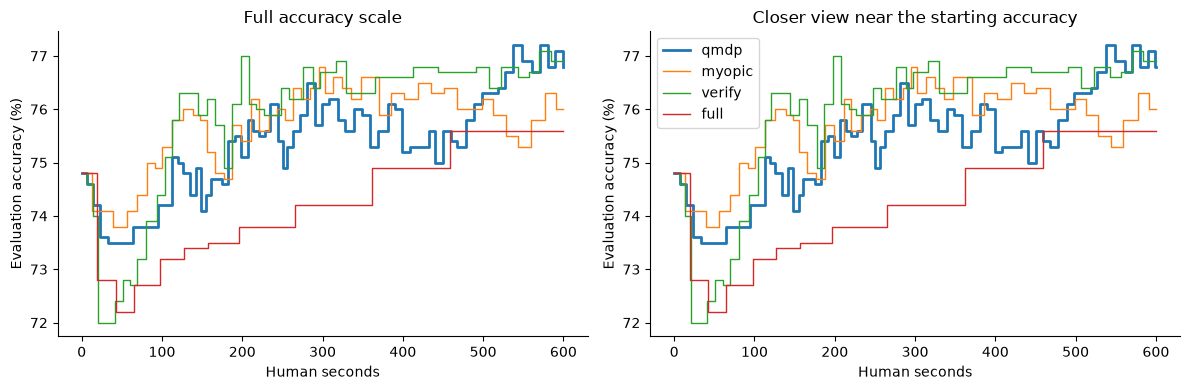

In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for _, run in demos.iterrows():
    curve = pd.read_csv(project / run.run_folder / 'accuracy_curve.csv')
    times = np.r_[curve.seconds, 600]
    accuracy = np.r_[curve.accuracy_percent, curve.accuracy_percent.iloc[-1]]
    for ax in axes:
        ax.step(times, accuracy, where='post', label=run.policy, linewidth=2 if run.policy=='qmdp' else 1)
axes[0].set(title='Full accuracy scale', xlabel='Human seconds', ylabel='Evaluation accuracy (%)')
axes[1].set(title='Closer view near the starting accuracy', xlabel='Human seconds', ylabel='Evaluation accuracy (%)')
axes[1].legend()
show_plot('01_classifier_accuracy_over_human_seconds')

## 6. Inspect actual returned answers
The audit below is for inspection after the run. The `correct` column is private simulator evaluation information: the learner never receives it.
Training used only the returned answer, model suggestions, and estimated reliability.

In [7]:
qmdp_folder = project / demos.loc[demos.policy=='qmdp','run_folder'].iloc[0]
answers = pd.read_csv(qmdp_folder / 'answer_audit.csv.gz')
answered = answers[answers.accepted & answers.action.isin([1,2,3])]
display(answered[['seconds','image_id','action','answer','top_one','top_two','estimated_reliability','correct']].head(12).round(3))
display(answers.loc[~answers.accepted,['start_seconds','seconds','action','answer','accepted']])

,seconds,image_id,action,answer,top_one,top_two,estimated_reliability,correct
0,0.666,5352,1,1,2,3,0.987,True
1,1.511,5092,1,0,9,5,0.996,True
2,2.284,7711,1,1,2,0,0.994,True
3,2.822,5933,1,0,4,3,0.983,True
4,3.635,74,1,1,9,3,0.994,True
5,4.178,9582,1,0,5,7,0.993,True
6,4.567,6157,1,0,0,7,0.996,True
7,5.399,9876,1,1,5,8,0.994,True
8,6.181,1858,1,1,2,4,0.995,True
9,6.741,1638,1,0,4,7,0.993,True


,start_seconds,seconds,action,answer,accepted
625,599.256273,600.0,1,-1,False


## 7. Compare question choices and acquired-label noise
A semantically wrong answer produces an invalid training target. We measure that privately after the experiment. The estimate used for training can still be wrong.

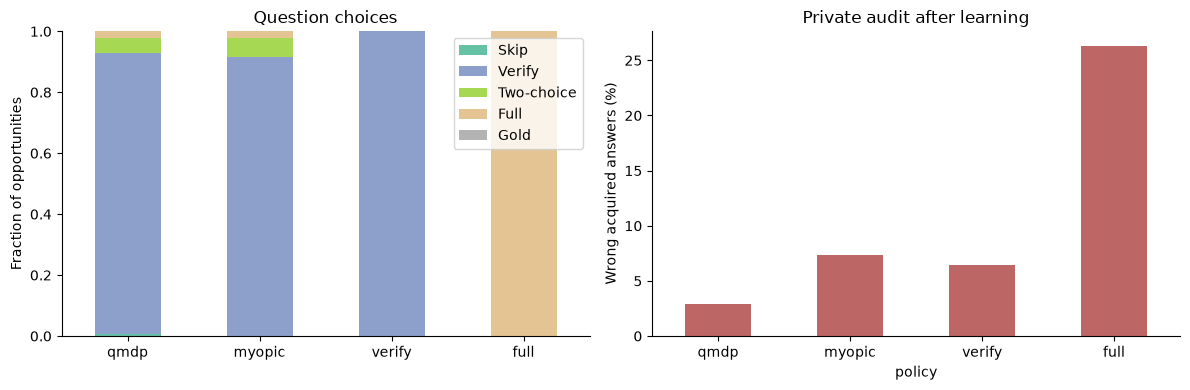

In [8]:
action_rows = []
for _, run in demos.iterrows():
    events = pd.read_csv(project / run.run_folder / 'answer_audit.csv.gz')
    counts = events.action.value_counts(normalize=True).reindex(range(5),fill_value=0)
    action_rows.append(pd.Series(counts.to_numpy(),index=['Skip','Verify','Two-choice','Full','Gold'],name=run.policy))
fig, axes = plt.subplots(1,2,figsize=(12,4))
pd.DataFrame(action_rows).plot.bar(stacked=True,ax=axes[0],colormap='Set2',rot=0)
axes[0].set(ylabel='Fraction of opportunities',title='Question choices')
demos.set_index('policy').acquired_error_rate.mul(100).plot.bar(ax=axes[1],color='#bd6666',rot=0)
axes[1].set(ylabel='Wrong acquired answers (%)',title='Private audit after learning')
show_plot('02_actions_and_label_noise')

## 8. Look at training targets without accessing true pool labels
These are stored instructions reconstructed from answers. A row with 9 allowed classes is a verification "no"; 8 means "neither"; 1 means a complete class name.

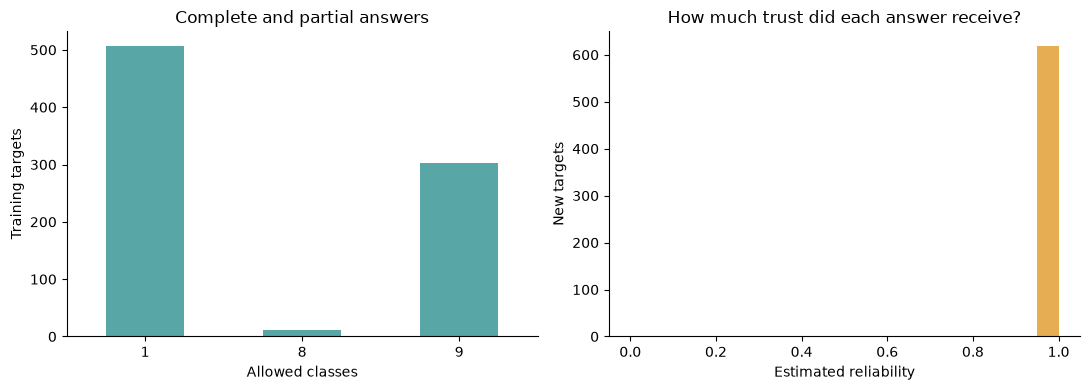

In [9]:
with np.load(qmdp_folder / 'training_targets.npz') as saved:
    target_counts = saved['allowed'].sum(axis=1)
    target_weights = saved['weights']
fig, axes = plt.subplots(1,2,figsize=(11,4))
pd.Series(target_counts).value_counts().sort_index().plot.bar(ax=axes[0],color='#58a6a6',rot=0)
axes[0].set(xlabel='Allowed classes',ylabel='Training targets',title='Complete and partial answers')
axes[1].hist(target_weights[200:],bins=np.linspace(0,1,21),color='#e7ad52')
axes[1].set(xlabel='Estimated reliability',ylabel='New targets',title='How much trust did each answer receive?')
show_plot('03_partial_targets_and_weights')

## 9. Run the scientific checks
We test the loss direction, correct conversion of partial answers, censored responses,
time sampling, and the private-state boundary. Passing these checks does not establish
a performance advantage; the repeated study does that assessment.

In [10]:
import subprocess
checks = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=project,capture_output=True,text=True)
print(checks.stdout + checks.stderr)
assert checks.returncode == 0
print('Next: Notebook 10 repeats the experiment and compares accuracy and time-to-target.')

test_answer_count_mode_is_unchanged (test_lapse_seconds.LapseSecondsChecks.test_answer_count_mode_is_unchanged) ... ok
test_onset_draw_is_shared_across_policies (test_lapse_seconds.LapseSecondsChecks.test_onset_draw_is_shared_across_policies) ... ok
test_pauses_count_as_time_only_in_seconds_mode (test_lapse_seconds.LapseSecondsChecks.test_pauses_count_as_time_only_in_seconds_mode) ... ok
test_seconds_mode_starts_at_its_scheduled_second (test_lapse_seconds.LapseSecondsChecks.test_seconds_mode_starts_at_its_scheduled_second) ... ok
test_stage1_case_lists (test_lapse_seconds.LapseSecondsChecks.test_stage1_case_lists) ... ok
test_stage2_case_lists (test_lapse_seconds.LapseSecondsChecks.test_stage2_case_lists) ... ok
test_stage2_onset_range_reaches_every_shift (test_lapse_seconds.LapseSecondsChecks.test_stage2_onset_range_reaches_every_shift) ... ok
test_deployable_planner_does_not_copy_the_true_world (test_review_fixes.ReviewFixChecks.test_deployable_planner_does_not_copy_the_true_world) .